# Oficina de Exploração do Saeb 2023 — Pernambuco (9º Ano EF)

- **Recorte:** Microdados do **Saeb 2023** (`TS_ALUNO_9EF.csv`) · **9º ano do Ensino Fundamental** (`ID_SERIE = 9`) · **Pernambuco** (`ID_UF = 26`, Região Nordeste) · `1 linha = 1 estudante`.
- **Ponte com o Censo Escolar 2023:** na oficina anterior (*Escada Tecnológica*), analisamos a infraestrutura digital declarada pela escola. O Saeb 2023 preenche duas lacunas centrais: **acesso à internet/dispositivos na casa do estudante** e **proficiência medida em Matemática e Língua Portuguesa**.
- **Compatibilidade entre dicionários (Saeb 2023 × Censo 2023):**
  - **Batem:** `ID_SAEB`=`NU_ANO_CENSO` (`2023`), `ID_REGIAO`=`CO_REGIAO`, `ID_UF`=`CO_UF` (`26`), `ID_LOCALIZACAO`=`TP_LOCALIZACAO` (`1`=Urbana, `2`=Rural); `IN_PUBLICA` bate com `TP_DEPENDENCIA` recodificada (`{1,2,3}→1`, `{4}→0`).
  - **Não batem (LGPD):** `ID_ESCOLA` e `ID_MUNICIPIO` no Saeb são **máscaras fictícias iniciadas por `6`** (0 sobreposição com `CO_ENTIDADE`/`CO_MUNICIPIO` do Censo), mas batem 100% internamente entre as tabelas do próprio Saeb.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

UF_CODIGO, UF_SIGLA, UF_NOME = 26, "PE", "Pernambuco"
BASE_DIR = os.path.abspath("..") if os.path.basename(os.getcwd()) == "oficina_saeb_2023" else os.path.abspath(".")
PATH_SAEB_9EF = os.path.join(BASE_DIR, "MICRODADOS_SAEB_2023", "DADOS", "TS_ALUNO_9EF.csv")
DIR_SAIDAS = os.path.join(BASE_DIR, "oficina_saeb_2023", "saidas")
os.makedirs(DIR_SAIDAS, exist_ok=True)

COLS = [
    "ID_SAEB", "ID_UF", "ID_MUNICIPIO", "ID_ESCOLA", "IN_PUBLICA", "ID_LOCALIZACAO",
    "ID_ALUNO", "IN_SITUACAO_CENSO", "IN_PREENCHIMENTO_QUESTIONARIO",
    "PESO_ALUNO_MT", "PESO_ALUNO_LP",
    "TX_RESP_Q13b", "TX_RESP_Q12b", "TX_RESP_Q12g",
    "PROFICIENCIA_MT_SAEB", "PROFICIENCIA_LP_SAEB"
]

df = pd.concat(
    [c[c["ID_UF"] == UF_CODIGO] for c in pd.read_csv(PATH_SAEB_9EF, sep=";", encoding="latin1", usecols=COLS, chunksize=250_000, low_memory=False)],
    ignore_index=True
)

ficha = pd.DataFrame([
    ("Edição / Etapa / Território", "Saeb 2023 · 9º ano EF · Pernambuco (ID_UF = 26)"),
    ("Total de registros (1 linha = 1 estudante)", f"{len(df):,}"),
    ("Escolas / Municípios distintos (mascarados)", f"{df['ID_ESCOLA'].nunique():,} escolas · {df['ID_MUNICIPIO'].nunique():,} municípios"),
    ("Rede (IN_PUBLICA)", f"Pública: {(df['IN_PUBLICA']==1).sum():,} | Privada (amostral): {(df['IN_PUBLICA']==0).sum():,}"),
    ("Localização (ID_LOCALIZACAO)", f"Urbana: {(df['ID_LOCALIZACAO']==1).sum():,} | Rural: {(df['ID_LOCALIZACAO']==2).sum():,}"),
    ("Consistentes com Censo 2023", f"{(df['IN_SITUACAO_CENSO']==1).sum():,} ({(df['IN_SITUACAO_CENSO']==1).mean()*100:.1f}%)"),
    ("Proficiência válida (MT / LP)", f"{df['PROFICIENCIA_MT_SAEB'].notna().sum():,} ({df['PROFICIENCIA_MT_SAEB'].notna().mean()*100:.1f}%)"),
    ("Questionário preenchido / Peso válido", f"{(df['IN_PREENCHIMENTO_QUESTIONARIO']==1).sum():,} / {(df['PESO_ALUNO_MT'].fillna(0)>0).sum():,}"),
], columns=["Item", "Recorte Pernambuco (PE)"])

display(ficha)

,Item,Recorte Pernambuco (PE)
0,Edição / Etapa / Território,Saeb 2023 · 9º ano EF · Pernambuco (ID_UF = 26)
1,Total de registros (1 linha = 1 estudante),"109,542"
2,Escolas / Municípios distintos (mascarados),"1,450 escolas · 185 municípios"
3,Rede (IN_PUBLICA),"Pública: 107,556 | Privada (amostral): 1,986"
4,Localização (ID_LOCALIZACAO),"Urbana: 91,505 | Rural: 18,037"
5,Consistentes com Censo 2023,"108,470 (99.0%)"
6,Proficiência válida (MT / LP),"96,313 (87.9%)"
7,Questionário preenchido / Peso válido,"96,150 / 95,947"


---
## As 5 Variáveis Selecionadas (`TS_ALUNO_9EF.csv`)

| Coluna escolhida | O que registra | Valores válidos e códigos especiais (Dicionário Saeb 2023) |
|---|---|---|
| `TX_RESP_Q13b` | Na sua casa tem: Rede Wi-Fi | **Válidos:** `A`=Não; `B`=Sim · **Especiais:** `.`=Branco; `*`=Nulo; vazio (`NaN`) |
| `TX_RESP_Q12b` | Quantos existem na sua casa: Computador (ou notebook) | **Válidos:** `A`=Nenhum; `B`=1; `C`=2; `D`=3 ou mais · **Especiais:** `.`=Branco; `*`=Nulo; vazio (`NaN`) |
| `TX_RESP_Q12g` | Quantos existem na sua casa: Celular com internet (smartphone) | **Válidos:** `A`=Nenhum; `B`=1; `C`=2; `D`=3 ou mais · **Especiais:** `.`=Branco; `*`=Nulo; vazio (`NaN`) |
| `PROFICIENCIA_MT_SAEB` | Proficiência em Matemática (escala Saeb: média 250, DP 50) | **Válidos:** contínuo (presentes, ≥3 itens, consistentes com Censo) · **Especial:** `NaN`=ausente/inválido |
| `PROFICIENCIA_LP_SAEB` | Proficiência em Língua Portuguesa (escala Saeb: média 250, DP 50) | **Válidos:** contínuo (presentes, ≥3 itens, consistentes com Censo) · **Especial:** `NaN`=ausente/inválido |

In [2]:
# 4.1 Tabela consolidada das 3 variáveis categóricas (denominador = respostas válidas; ausências separadas)
LEGENDAS = {
    "TX_RESP_Q13b": ("Rede Wi-Fi em casa", {"A": "Não", "B": "Sim"}),
    "TX_RESP_Q12b": ("Computador/notebook em casa", {"A": "Nenhum", "B": "1", "C": "2", "D": "3 ou mais"}),
    "TX_RESP_Q12g": ("Smartphone c/ internet em casa", {"A": "Nenhum", "B": "1", "C": "2", "D": "3 ou mais"}),
}

rows_cat = []
for col, (desc, mapa) in LEGENDAS.items():
    s = df[col]
    n_val = int(s.isin(mapa.keys()).sum())
    for k, rotulo in mapa.items():
        qtd = int((s == k).sum())
        rows_cat.append({
            "Variável": col, "Descrição": desc, "Tipo": "Válido", "Categoria": f"{k} - {rotulo}",
            "Quantidade": qtd, "% sobre válidos": round(qtd / n_val * 100, 1), "Denominador válido": n_val
        })
    for k, rotulo in [(".", "Branco"), ("*", "Nulo")]:
        qtd = int((s == k).sum())
        rows_cat.append({
            "Variável": col, "Descrição": desc, "Tipo": "Especial/Ausência", "Categoria": f"{k} - {rotulo}",
            "Quantidade": qtd, "% sobre válidos": np.nan, "Denominador válido": n_val
        })

df_cat = pd.DataFrame(rows_cat)
print("=== Frequências das 3 variáveis categóricas (PE, Saeb 2023) ===")
display(df_cat)

# 4.2 Resumo numérico das 2 proficiências (Matemática e Língua Portuguesa)
def resumo_num(col, peso, nome):
    v = df[col].dropna()
    mp = df[col].notna() & (df[peso].fillna(0) > 0)
    return {
        "Disciplina": nome, "Coluna": col,
        "N válidos": int(len(v)), "Ausentes (NaN)": int(df[col].isna().sum()),
        "% Ausentes": round(df[col].isna().mean() * 100, 1),
        "Média simples": round(v.mean(), 2), "Mín": round(v.min(), 2), "Máx": round(v.max(), 2),
        "Média ponderada (peso)": round(np.average(df.loc[mp, col], weights=df.loc[mp, peso]), 2),
    }

df_prof = pd.DataFrame([
    resumo_num("PROFICIENCIA_MT_SAEB", "PESO_ALUNO_MT", "Matemática"),
    resumo_num("PROFICIENCIA_LP_SAEB", "PESO_ALUNO_LP", "Língua Portuguesa"),
])
print("\n=== Resumo das proficiências em Matemática e Língua Portuguesa (PE, Saeb 2023) ===")
display(df_prof)

=== Frequências das 3 variáveis categóricas (PE, Saeb 2023) ===


,Variável,Descrição,Tipo,Categoria,Quantidade,% sobre válidos,Denominador válido
0,TX_RESP_Q13b,Rede Wi-Fi em casa,Válido,A - Não,8172,9.0,90322
1,TX_RESP_Q13b,Rede Wi-Fi em casa,Válido,B - Sim,82150,91.0,90322
2,TX_RESP_Q13b,Rede Wi-Fi em casa,Especial/Ausência,. - Branco,18642,NaN,90322
3,TX_RESP_Q13b,Rede Wi-Fi em casa,Especial/Ausência,* - Nulo,578,NaN,90322
4,TX_RESP_Q12b,Computador/notebook em casa,Válido,A - Nenhum,58696,67.4,87081
5,TX_RESP_Q12b,Computador/notebook em casa,Válido,B - 1,19482,22.4,87081
6,TX_RESP_Q12b,Computador/notebook em casa,Válido,C - 2,6208,7.1,87081
7,TX_RESP_Q12b,Computador/notebook em casa,Válido,D - 3 ou mais,2695,3.1,87081
8,TX_RESP_Q12b,Computador/notebook em casa,Especial/Ausência,. - Branco,19256,NaN,87081
9,TX_RESP_Q12b,Computador/notebook em casa,Especial/Ausência,* - Nulo,3205,NaN,87081



=== Resumo das proficiências em Matemática e Língua Portuguesa (PE, Saeb 2023) ===


,Disciplina,Coluna,N válidos,Ausentes (NaN),% Ausentes,Média simples,Mín,Máx,Média ponderada (peso)
0,Matemática,PROFICIENCIA_MT_SAEB,96313,13229,12.1,248.59,108.84,419.96,255.14
1,Língua Portuguesa,PROFICIENCIA_LP_SAEB,96313,13229,12.1,250.98,125.11,379.45,257.50


,WiFi,N_validos,Media_MT,Media_LP
0,Sem Wi-Fi,8147,239.18,239.1
1,Com Wi-Fi,81922,250.38,253.0


,Computador,N_validos,Media_MT,Media_LP
0,Nenhum,58541,246.03,248.07
1,1,19421,258.79,262.56
2,2,6186,257.13,260.22
3,3 ou mais,2682,257.72,256.49



=== Correlação de Spearman (exploratória, sem peso) ===


,Matemática,Língua Portuguesa
Wi-Fi (Q13b),0.064,0.081
Computador (Q12b),0.111,0.123
Smartphone (Q12g),0.102,0.112


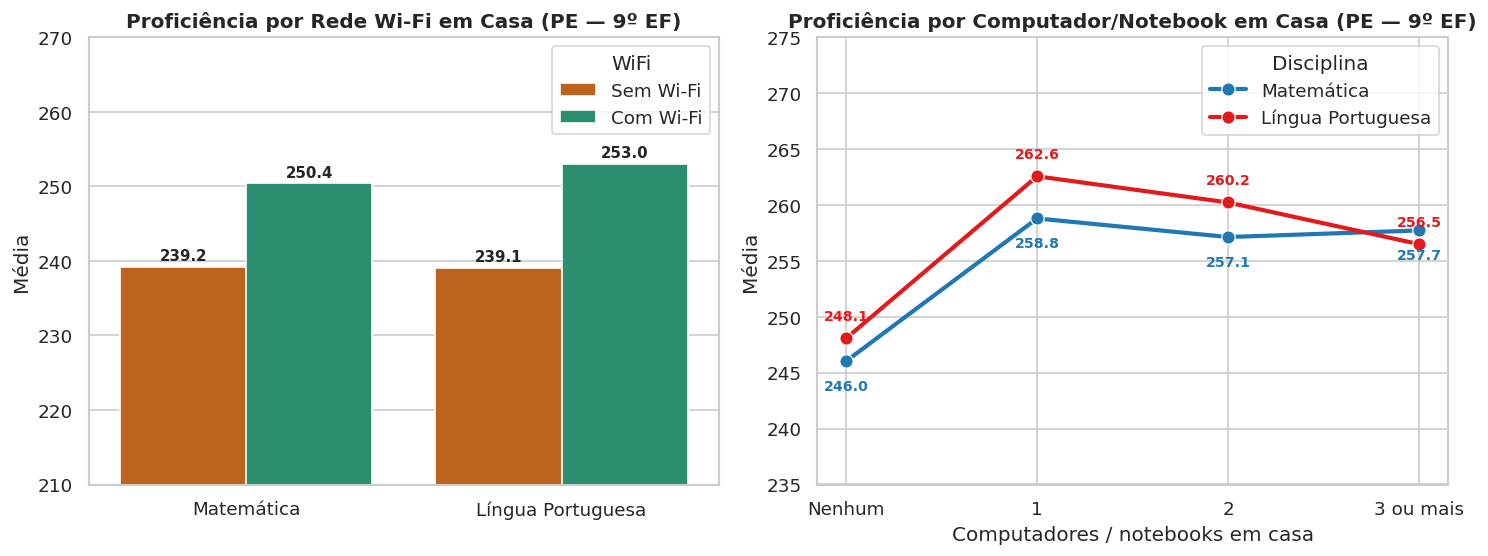

In [3]:
# Comparação 1: Com Wi-Fi vs. Sem Wi-Fi (TX_RESP_Q13b)
df_wifi = df[df["TX_RESP_Q13b"].isin(["A", "B"])].copy()
df_wifi["WiFi"] = df_wifi["TX_RESP_Q13b"].map({"A": "Sem Wi-Fi", "B": "Com Wi-Fi"})
comp_wifi = (
    df_wifi.groupby("WiFi")
    .agg(N_validos=("PROFICIENCIA_MT_SAEB", lambda s: s.notna().sum()),
         Media_MT=("PROFICIENCIA_MT_SAEB", "mean"),
         Media_LP=("PROFICIENCIA_LP_SAEB", "mean"))
    .round(2).reindex(["Sem Wi-Fi", "Com Wi-Fi"]).reset_index()
)

# Comparação 2: Computador/notebook em casa (TX_RESP_Q12b)
df_pc = df[df["TX_RESP_Q12b"].isin(["A", "B", "C", "D"])].copy()
df_pc["Computador"] = df_pc["TX_RESP_Q12b"].map({"A": "Nenhum", "B": "1", "C": "2", "D": "3 ou mais"})
comp_pc = (
    df_pc.groupby("Computador")
    .agg(N_validos=("PROFICIENCIA_MT_SAEB", lambda s: s.notna().sum()),
         Media_MT=("PROFICIENCIA_MT_SAEB", "mean"),
         Media_LP=("PROFICIENCIA_LP_SAEB", "mean"))
    .round(2).reindex(["Nenhum", "1", "2", "3 ou mais"]).reset_index()
)

# Correlação exploratória de Spearman (sem peso)
df_corr = pd.DataFrame({
    "Wi-Fi (Q13b)": df["TX_RESP_Q13b"].map({"A": 0, "B": 1}),
    "Computador (Q12b)": df["TX_RESP_Q12b"].map({"A": 0, "B": 1, "C": 2, "D": 3}),
    "Smartphone (Q12g)": df["TX_RESP_Q12g"].map({"A": 0, "B": 1, "C": 2, "D": 3}),
    "Matemática": df["PROFICIENCIA_MT_SAEB"],
    "Língua Portuguesa": df["PROFICIENCIA_LP_SAEB"],
}).corr(method="spearman").loc[["Wi-Fi (Q13b)", "Computador (Q12b)", "Smartphone (Q12g)"], ["Matemática", "Língua Portuguesa"]].round(3)

display(comp_wifi)
display(comp_pc)
print("\n=== Correlação de Spearman (exploratória, sem peso) ===")
display(df_corr)

# Gráfico compacto de 2 painéis (Matemática vs. Língua Portuguesa)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), dpi=120)

w_melt = comp_wifi.melt("WiFi", ["Media_MT", "Media_LP"], "Disciplina", "Média")
w_melt["Disciplina"] = w_melt["Disciplina"].map({"Media_MT": "Matemática", "Media_LP": "Língua Portuguesa"})
sns.barplot(data=w_melt, x="Disciplina", y="Média", hue="WiFi", palette=["#d95f02", "#1b9e77"], ax=axes[0])
axes[0].set_title("Proficiência por Rede Wi-Fi em Casa (PE — 9º EF)", fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylim(210, 270)
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.1f", fontsize=9, fontweight="bold", padding=2)

p_melt = comp_pc.melt("Computador", ["Media_MT", "Media_LP"], "Disciplina", "Média")
p_melt["Disciplina"] = p_melt["Disciplina"].map({"Media_MT": "Matemática", "Media_LP": "Língua Portuguesa"})
sns.lineplot(data=p_melt, x="Computador", y="Média", hue="Disciplina", marker="o", linewidth=2.5, markersize=8,
             palette=["#1f78b4", "#e31a1c"], ax=axes[1])
axes[1].set_title("Proficiência por Computador/Notebook em Casa (PE — 9º EF)", fontweight="bold")
axes[1].set_xlabel("Computadores / notebooks em casa")
axes[1].set_ylim(235, 275)
for _, r in comp_pc.iterrows():
    axes[1].text(r["Computador"], r["Media_MT"] - 2.6, f"{r['Media_MT']:.1f}", ha="center", fontsize=8.5, color="#1f78b4", fontweight="bold")
    axes[1].text(r["Computador"], r["Media_LP"] + 1.6, f"{r['Media_LP']:.1f}", ha="center", fontsize=8.5, color="#e31a1c", fontweight="bold")

plt.tight_layout()
fig_path = os.path.join(DIR_SAIDAS, "evidencia_saeb_PE_2023.png")
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()

---
## Achado, Dúvida, Limite e Perguntas para Continuar

- **Achado:** Em Pernambuco (Saeb 2023, 9º ano EF, `N = 109.542` estudantes em `1.450` escolas), **91,0%** têm Wi-Fi e **97,8%** têm smartphone com internet, mas **67,4%** não possuem computador/notebook em casa. Quem tem Wi-Fi apresenta maior média simples em **Matemática** (`250,38` vs. `239,18`; **+11,20 pts**) e em **Língua Portuguesa** (`253,00` vs. `239,10`; **+13,90 pts**). Na correlação de Spearman, possuir computador apresentou associação maior que apenas Wi-Fi (`MT: 0,111 vs. 0,064`; `LP: 0,123 vs. 0,081`).
- **Dúvida:** As ausências no questionário (`17,0%` em branco em `TX_RESP_Q13b`) e na prova (`12,1%` sem nota) concentram-se em grupos mais vulneráveis? Ao controlar pelo `INSE_ALUNO` e aplicar `PESO_ALUNO_MT`/`LP`, a associação continua maior em Língua Portuguesa ou em Matemática?
- **Limite:** (1) Diferença entre grupos **não prova causalidade** (internet acompanha renda/escolaridade familiar); (2) médias simples descrevem apenas o recorte — resultados populacionais exigem pesos (`PESO_ALUNO_MT`/`LP`); (3) por LGPD, `ID_ESCOLA` e `ID_MUNICIPIO` são mascarados (`6...`), impedindo cruzamento direto por escola com o Censo Escolar 2023.

### Duas Perguntas para Continuar (Base: `TS_ALUNO_9EF.csv`, PE, Saeb 2023)
1. ⭐ **[PRIORIDADE] Contexto de Matemática:** *Qual é a correlação entre o acesso à internet/dispositivos em casa (`TX_RESP_Q13b`, `TX_RESP_Q12b`, `TX_RESP_Q12g`) e a proficiência em **Matemática** (`PROFICIENCIA_MT_SAEB`) no 9º ano de Pernambuco, controlando por `INSE_ALUNO`, `ID_LOCALIZACAO` e usando `PESO_ALUNO_MT`?*
2. **Contexto de Língua Portuguesa:** *Qual é a correlação entre o acesso à internet/dispositivos em casa (`TX_RESP_Q13b`, `TX_RESP_Q12b`, `TX_RESP_Q12g`) e a proficiência em **Língua Portuguesa** (`PROFICIENCIA_LP_SAEB`) no 9º ano de Pernambuco, controlando por `INSE_ALUNO` e usando `PESO_ALUNO_LP`, e como ela difere da observada em Matemática?*

- **Justificativa da prioridade:** Iniciar por **Matemática** (Pergunta 1) prioriza a disciplina com menor média em PE e define o protocolo ponderado e controlado por INSE para replicação idêntica em **Língua Portuguesa** (Pergunta 2).
- **Primeira ação:** Auditar as ausências (`IN_PRESENCA_MT`/`LP`, `IN_INSE`), criar uma variável combinada de conectividade domiciliar (*Sem internet*, *Só celular*, *Wi-Fi sem PC*, *Wi-Fi + PC*) e validar o cálculo ponderado com `PESO_ALUNO_MT` e `PESO_ALUNO_LP`.

In [4]:
# Exportar planilha enxuta para a pasta da equipe na nuvem
df_cinco = pd.DataFrame([
    ("TX_RESP_Q13b", "Na sua casa tem: Rede Wi-Fi", "A=Não; B=Sim | Especiais: .=Branco, *=Nulo, NaN"),
    ("TX_RESP_Q12b", "Quantos existem na casa: Computador/notebook", "A=Nenhum; B=1; C=2; D=3 ou mais | Especiais: ., *, NaN"),
    ("TX_RESP_Q12g", "Quantos existem na casa: Smartphone c/ internet", "A=Nenhum; B=1; C=2; D=3 ou mais | Especiais: ., *, NaN"),
    ("PROFICIENCIA_MT_SAEB", "Proficiência em Matemática (escala Saeb)", "Numérico contínuo (média 250, DP 50) | Especial: NaN"),
    ("PROFICIENCIA_LP_SAEB", "Proficiência em Língua Portuguesa (escala Saeb)", "Numérico contínuo (média 250, DP 50) | Especial: NaN"),
], columns=["Coluna escolhida", "O que registra", "Valores válidos e códigos especiais"])

excel_path = os.path.join(DIR_SAIDAS, "planilha_analise_saeb_2023_PE.xlsx")
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    ficha.to_excel(writer, sheet_name="Ficha_Recorte_PE", index=False)
    df_cinco.to_excel(writer, sheet_name="Cinco_Variaveis", index=False)
    df_cat.to_excel(writer, sheet_name="Frequencias_Categoricas", index=False)
    df_prof.to_excel(writer, sheet_name="Resumo_Proficiencias", index=False)
    comp_wifi.to_excel(writer, sheet_name="Comparacao_WiFi", index=False)
    comp_pc.to_excel(writer, sheet_name="Comparacao_Computador", index=False)
    df_corr.reset_index().to_excel(writer, sheet_name="Correlacoes_Spearman", index=False)

print("Planilha atualizada:", excel_path)

Planilha atualizada: /home/jorge/Documentos/Faculdade/Materias-Faculdade/mineracao-educacional/oficina_saeb_2023/saidas/planilha_analise_saeb_2023_PE.xlsx
